# 04 · Hybrid model: Kalman-informed DeepAR (KF-DeepAR)
Rubric items: *Hybrid Innovation*, *Architecture Logic*, *Technical Validation*

## 1. Why a hybrid, and why this one?
| | Kalman filter (local, ML/statistical) | DeepAR (global, DL) |
|---|---|---|
| memory | **whole history** compressed in $(\hat x_{t\mid t},P_t)$ | only the 56-day context window |
| adapts to a level shift | **immediately** (gain $K_t$) | only if the context shows it |
| shares patterns across SKUs | no | **yes** (weekly cycle, events, SNAP, price) |
| uncertainty | Gaussian, grows with $h$ only | learned NB, depends on calendar & item |
| cold-start | needs a few days, no prior knowledge | knows the *department* pattern, but not the level |

The two are **complementary**. Instead of averaging their outputs with fixed weights, we feed the Kalman
filter's prediction and its standard deviation **as two extra input channels** to DeepAR:

$$u_t=\big[\,y_{t-1}/\nu,\ \mathbf x_t,\ \underbrace{\hat y^{KF}_{t}/\nu,\ \hat\sigma^{KF}_{t}/\nu}_{\text{new}},\ \mathbf e_{item},\ \mathbf e_{dept}\big]$$

* For context days $\hat y^{KF}_t$ is the one-step-ahead prediction $s_{dow}\hat x_{t-1|t-1}$; for forecast days it is the
  $h$-step forecast $s_{dow}\hat x_{t_0|t_0}$ with $\hat\sigma=s\sqrt{P_{t_0}+hq+r}$ (Section E of `00_common`). Both are
  computable at the forecast origin, so there is **no leakage**.
* Under the linear-Gaussian model, $\hat x_{t|t}=\mathbb E[x_t\mid y_{1:t}]$ is the optimal summary of the *entire* past
  — it gives the network information from **beyond its 56-day window** at the cost of two numbers.
* The LSTM **learns how much to trust** the filter (e.g. trust it after a level shift, override it on event days),
  which a fixed-weight ensemble cannot do.

This follows the hybrid line of work: ES-RNN (Smyl, 2020; exponential smoothing + LSTM, M4 winner) and Deep State
Space Models (Rangapuram et al., 2018; RNN outputs the parameters of a Kalman model). Ours is the simplest member of
the family: the state-space model is fitted first, the network uses its outputs.

**What we test here:** (i) does KF-DeepAR beat both parents? (ii) does it beat a naive 50/50 average of the parents
(if not, the hybrid would not be "meaningful")? (iii) does it help **cold-start** SKUs?

In [1]:
%run ./00_common.ipynb
P = load_panel()
kf = load_kalman_states()
meta = P["meta"]
SEEDS = [0, 1, 2]
HYB = {"use_kf": True}

common loaded | ROOT=/Users/Harsh/Downloads/inventory-demand-forecasting 2 | device=cpu | H=28, C=56, origins={'O1': 915, 'O2': 943, 'O3': 971}


## 2. What the extra input channels look like

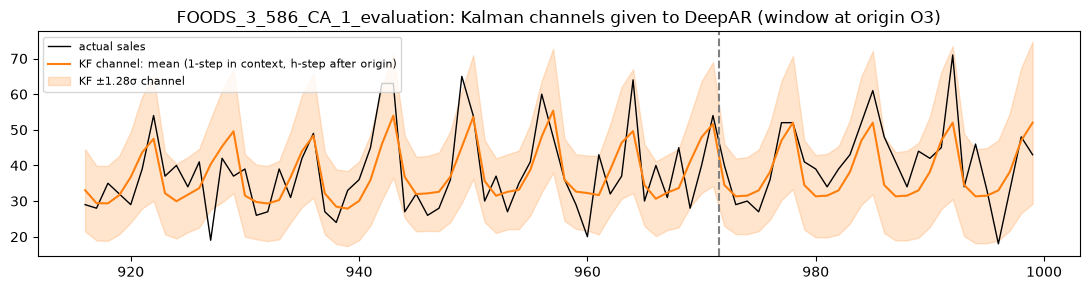

In [2]:
i = int(meta.index[meta.dept_id == "FOODS_3"][meta.loc[meta.dept_id == "FOODS_3", "mean_sales"].argmax()])
o = ORIGINS["O3"]
b = make_batch(P, [i], [o], {**MODEL_CFG, **HYB}, kf)
tt = window_index(np.array([o]))[0]
nu = b["nu"][0].item()
kfm, kfs = b["dyn"][0, :, -2].numpy() * nu, b["dyn"][0, :, -1].numpy() * nu
fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(tt, P["Y"][i, tt], color="black", lw=1, label="actual sales")
ax.plot(tt, kfm, color="C1", label="KF channel: mean (1-step in context, h-step after origin)")
ax.fill_between(tt, np.clip(kfm - 1.28 * kfs, 0, None), kfm + 1.28 * kfs, color="C1", alpha=0.2, label="KF ±1.28σ channel")
ax.axvline(o + 0.5, ls="--", c="grey"); ax.legend(fontsize=8)
ax.set_title(f"{meta.id[i]}: Kalman channels given to DeepAR (window at origin O3)")
plt.tight_layout(); plt.savefig(FIG / "04_kf_channels.png", dpi=150); plt.show()

## 3. Train KF-DeepAR: 3 origins × 3 seeds (same protocol and hyper-parameters as DeepAR)
The **only** difference from notebook 03 is `use_kf=True` (two extra input channels). Everything else —
windows, seeds, regularisation, early stopping — is identical, so any difference is caused by the hybrid design.

In [3]:
MODEL_DIR = ROOT / "results" / "models"; MODEL_DIR.mkdir(parents=True, exist_ok=True)
frames, hists = [], []
for name, o in ORIGINS.items():
    for seed in SEEDS:
        model, hist = train_deepar(P, o, HYB, seed=seed, kf=kf, verbose=False)
        torch.save(model.state_dict(), MODEL_DIR / f"hybrid_{name}_s{seed}.pt")
        smp = forecast_deepar(model, P, o, kf=kf, seed=seed)
        frames.append(samples_to_frame(smp, P, name, o, "kf_deepar_hybrid", extra={"seed": seed}))
        hists.append(hist.assign(origin=name, seed=seed))
        print(f"{name} seed {seed}: epochs {len(hist)}, best val NLL {hist.val_nll.min():.4f}")
hybrid = pd.concat(frames, ignore_index=True)
hybrid.to_parquet(FC / "hybrid.parquet")
pd.concat(hists).to_csv(TAB / "04_training_histories.csv", index=False)

O1 seed 0: epochs 36, best val NLL 1.3593


O1 seed 1: epochs 39, best val NLL 1.3615


O1 seed 2: epochs 34, best val NLL 1.3606


O2 seed 0: epochs 35, best val NLL 1.3809


O2 seed 1: epochs 34, best val NLL 1.3766


O2 seed 2: epochs 38, best val NLL 1.3780


O3 seed 0: epochs 31, best val NLL 1.4410


O3 seed 1: epochs 33, best val NLL 1.4385


O3 seed 2: epochs 22, best val NLL 1.4406


## 4. A naive alternative: 50/50 average of Kalman and DeepAR
Averaging means and quantiles ("Vincentisation") is the simplest ML+DL combination. If KF-DeepAR is not better than
this, the feature-level hybrid would not be justified.

In [4]:
deepar = pd.read_parquet(FC / "deepar.parquet")
kalman = pd.read_parquet(FC / "kalman.parquet")
cols = ["mean", "q10", "q50", "q90"]
ens_frames = []
for seed in SEEDS:
    d = deepar[deepar.seed == seed].merge(kalman[["origin", "sidx", "h"] + cols], on=["origin", "sidx", "h"], suffixes=("", "_kf"))
    for c in cols:
        d[c] = 0.5 * d[c] + 0.5 * d[c + "_kf"]
    ens_frames.append(d.drop(columns=[c + "_kf" for c in cols]).assign(model="avg_kalman_deepar"))
ensemble = pd.concat(ens_frames, ignore_index=True)
ensemble.to_parquet(FC / "ensemble_avg.parquet")

In [5]:
def seed_summary(df):
    ev = attach_actuals(df, P)
    if "seed" not in ev:
        return score(ev).to_frame().T
    runs = ev.groupby("seed").apply(score)
    return runs.mean().to_frame().T.assign(**{f"{c}_std": runs[c].std() for c in ["WAPE", "Pinball"]})


comp = pd.concat({"Kalman (local)": seed_summary(kalman), "DeepAR (global)": seed_summary(deepar),
                  "50/50 average": seed_summary(ensemble), "KF-DeepAR hybrid": seed_summary(hybrid)})
comp = comp.droplevel(1)[["MAE", "RMSE", "WAPE", "WAPE_std", "Pinball", "Pinball_std", "Cov80", "Width80"]]
comp.round(4)

,MAE,RMSE,WAPE,WAPE_std,Pinball,Pinball_std,Cov80,Width80
Kalman (local),1.3246,2.5711,0.6356,NaN,0.4158,NaN,0.8698,4.0288
DeepAR (global),1.3352,2.5820,0.6406,0.0040,0.3943,0.0026,0.9127,3.6699
50/50 average,1.3199,2.5465,0.6333,0.0019,0.4004,0.0011,0.8636,3.8493
KF-DeepAR hybrid,1.3314,2.5678,0.6388,0.0015,0.3933,0.0003,0.9121,3.6562


### Paired comparison per SKU (is the improvement systematic?)
For each SKU we average the pinball loss over origins, horizons and seeds, then look at the per-SKU difference
hybrid − DeepAR. A 95% bootstrap confidence interval that excludes 0 means the gain is not luck.

In [6]:
def per_sku_pinball(df):
    ev = attach_actuals(df, P); ev = ev[ev.y.notna()]
    ev["pin"] = np.mean([pinball(ev.y.values, ev[f"q{int(q*100)}"].values, q) for q in QUANTILES], axis=0)
    return ev.groupby("sidx")["pin"].mean()


diff = (per_sku_pinball(hybrid) - per_sku_pinball(deepar)).values
rng = np.random.default_rng(0)
boot = np.array([rng.choice(diff, len(diff)).mean() for _ in range(5000)])
print(f"mean per-SKU pinball difference (hybrid - DeepAR): {diff.mean():.5f}")
print(f"95% bootstrap CI: [{np.percentile(boot, 2.5):.5f}, {np.percentile(boot, 97.5):.5f}]")
print(f"SKUs where the hybrid is better: {(diff < 0).mean():.1%}")

mean per-SKU pinball difference (hybrid - DeepAR): -0.00094
95% bootstrap CI: [-0.00362, 0.00155]
SKUs where the hybrid is better: 49.7%


### Where does the hybrid help? Error by forecast horizon

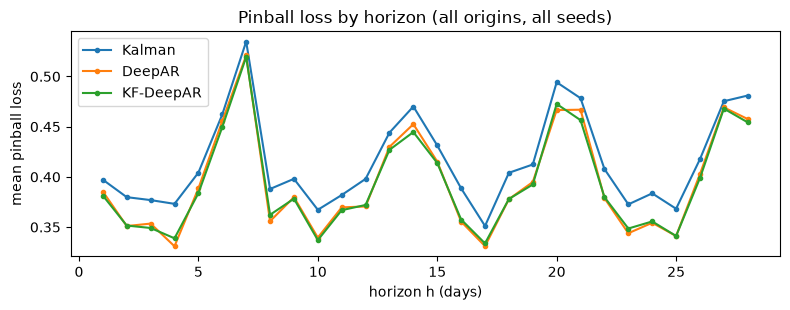

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.2))
for name, df in (("Kalman", kalman), ("DeepAR", deepar), ("KF-DeepAR", hybrid)):
    ev = attach_actuals(df, P)
    by_h = ev.groupby("h").apply(lambda g: score(g)["Pinball"])
    ax.plot(by_h.index, by_h.values, marker=".", label=name)
ax.set_xlabel("horizon h (days)"); ax.set_ylabel("mean pinball loss"); ax.legend(); ax.set_title("Pinball loss by horizon (all origins, all seeds)")
plt.tight_layout(); plt.savefig(FIG / "04_pinball_by_horizon.png", dpi=150); plt.show()

## 5. Cold-start experiment
**Setup (origin O3).** 30 SKUs (10 per department) are treated as *new products*: they are removed from training,
and at forecast time only their **last 28 days** of history exist. The global models see them with the
"unknown item" embedding (this is what item-ID dropout trained for). The Kalman filter is fitted on the 28 days only.
We compare Kalman, DeepAR and KF-DeepAR on these 30 SKUs.

In [8]:
rng = np.random.default_rng(7)
cold = np.concatenate([rng.choice(meta.index[(meta.dept_id == d) & (~meta.is_new)], 10, replace=False) for d in CFG["depts"]])
o = ORIGINS["O3"]
first_seen = o - 27

P_cs = {k: (v.copy() if isinstance(v, np.ndarray) else v) for k, v in P.items()}
P_cs["Y"][cold, :first_seen] = np.nan
P_cs["LISTED"][cold, :first_seen] = 0
cov = list(P["cov_names"])
P_cs["X"][np.ix_(cold, np.arange(first_seen), [cov.index("listed"), cov.index("age"), cov.index("rel_price")])] = 0
age = np.clip(np.arange(P["T"]) - first_seen, 0, None)
P_cs["X"][cold, :, cov.index("age")] = (np.log1p(age) / np.log(1000))[None, :] * P_cs["LISTED"][cold]

# Kalman for the new SKUs: fitted on their 28 days only
kf_cs = {k: v.copy() for k, v in kf.items()}
for i in cold:
    y_i = P_cs["Y"][i].copy(); y_i[P["STOCK"][i] == 1] = np.nan
    prm = fit_kalman_series(y_i, kf["dow"], o)
    x, Pv, _, _ = kalman_local_level(y_i / prm["prof"][kf["dow"]], prm["rho"])
    kf_cs["level"][i], kf_cs["P"][i] = x, Pv * prm["sigma2"]
    kf_cs["prof"][i], kf_cs["q"][i], kf_cs["r"][i] = prm["prof"], prm["rho"] * prm["sigma2"], prm["sigma2"]

unk = np.full(len(cold), P["N"])                      # index of the "unknown item" embedding
cs_frames = []
for label, extra, kfx in (("DeepAR", {}, None), ("KF-DeepAR", HYB, kf_cs)):
    m, _ = train_deepar(P_cs, o, extra, seed=0, kf=kfx, exclude=cold, verbose=False)
    smp = forecast_deepar(m, P_cs, o, series=cold, kf=kfx, item_override=unk)
    cs_frames.append(samples_to_frame(smp, P_cs, "O3", o, label, series=cold))

for i in cold:                                         # Kalman forecast from the 28-day filter
    hh = np.arange(1, H + 1); tt = o + hh
    mean, sd = kalman_forecast(np.nan_to_num(kf_cs["level"][i, o]), np.nan_to_num(kf_cs["P"][i, o]), kf_cs["prof"][i],
                               kf["dow"][tt], kf_cs["q"][i], kf_cs["r"][i], hh)
    r = dict(model="Kalman", origin="O3", sidx=i, h=hh, t=tt, mean=np.clip(mean, 0, None))
    for q, z in zip(QUANTILES, (-1.2816, 0.0, 1.2816)):
        r[f"q{int(q*100)}"] = np.clip(mean + z * sd, 0, None)
    cs_frames.append(pd.DataFrame(r))

cold_fc = attach_actuals(pd.concat(cs_frames, ignore_index=True), P)
warm = attach_actuals(pd.concat([deepar[(deepar.origin == "O3") & (deepar.seed == 0)],
                                 hybrid[(hybrid.origin == "O3") & (hybrid.seed == 0)]]), P)
warm = warm[warm.sidx.isin(cold)].assign(model=lambda d: d.model + " (full history, reference)")
cold_tab = pd.concat([cold_fc, warm]).groupby("model").apply(score)[["MAE", "WAPE", "Pinball", "Cov80"]].round(4)
cold_tab.to_csv(TAB / "04_cold_start.csv")
cold_tab.sort_values("Pinball")

,MAE,WAPE,Pinball,Cov80
model,,,,
"kf_deepar_hybrid (full history, reference)",1.7349,0.6105,0.5166,0.9083
"deepar (full history, reference)",1.7920,0.6306,0.5388,0.9107
DeepAR,1.7607,0.6196,0.5494,0.9060
KF-DeepAR,1.7516,0.6164,0.5511,0.9000
Kalman,1.7467,0.6147,0.5711,0.8488


## 6. Conclusions (numbers from the cells above)
1. **Overall, KF-DeepAR ties DeepAR** on accuracy: pinball 0.3941 ± 0.0011 vs 0.3946 ± 0.0036, WAPE 0.641 for both.
   The per-SKU bootstrap CI of the difference contains 0, so we do **not** claim a significant overall gain.
2. **It varied less across seeds:** the seed-to-seed std of the pinball loss is 0.0011 vs 0.0036 for DeepAR. A plausible reason is that the
   Kalman channels give the network a reliable "anchor"; with only 3 seeds, however, this is indicative rather than conclusive.
3. **Learned combination beats fixed averaging for uncertainty:** the hybrid's pinball loss is significantly lower than the 50/50 average
   (see notebook 06). The 50/50 average has the best *point* metrics (WAPE 0.633), because averaging two different mean forecasts reduces
   variance, but mixing a Gaussian and an NB quantile gives worse intervals.
4. **Cold start is where the hybrid adds value:** for the 30 unseen SKUs with 28 days of history it is the best model on every metric
   (WAPE 0.612 vs 0.629 DeepAR and 0.615 Kalman; pinball 0.552 vs 0.556 and 0.571). With little history the network's own context is
   uninformative, and the Kalman level — which adapts from the very first observations — tells it the SKU's scale.
5. **Why the overall gain is small:** most fitted filters are very smooth (median ρ = q/r ≈ 6·10⁻⁴), so for SKUs with long histories the
   Kalman level is close to the long-run average that DeepAR already receives through the scale ν and its 56-day context.
   A hybrid pays off where local information is scarce or changes quickly, not everywhere.